# RF-EMF exposure research rankings

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rwydaegh/rf-emf-leaderboard/blob/main/RF-EMF_research_rankings.ipynb)

> **Independently reproduced.** In an impartial audit, ChatGPT reran the code and reproduced every ranking. [Read the report](https://chatgpt.com/share/6af8ab58-7980-83ed-aca6-cc6e3aca135f).

Who publishes the most research on human exposure to radiofrequency electromagnetic fields (RF-EMF)?
This notebook counts it from open data.
The starting point is 84,602 papers from [OpenAlex](https://openalex.org), 1980–2026.
Claude Sonnet read the title and abstract of each paper and labeled its topic and study type.

By default, the notebook looks at dosimetric studies in peer-reviewed journals from 2016 to 2025. You can change that further down.
Choose *Runtime > Run all*. About a minute later, every table and figure is rebuilt from the data in this repository.

In [1]:
import os
if not os.path.exists("lb.py"):
    !git clone -q --depth 1 https://github.com/rwydaegh/rf-emf-leaderboard
    %cd rf-emf-leaderboard
import lb
lb.style()

## Summary

In [2]:
lb.summary()

- Wout Joseph (Ghent University) has the most peer-reviewed RF-EMF dosimetric papers of 2016–2025: 66. Next is Joe Wiart with 55.
- He has the most papers in every 5-year window from 2009–2013 to 2019–2023.
- Ghent University has the most papers of any university: 78. Next is Hanyang University with 58.
- 3 of the 6 authors with the most papers work or have worked at WAVES (UGent-imec): Wout Joseph, Luc Martens and Arno Thielens.
- Wout Joseph has the most papers in 4 sub-fields: field measurements, base stations & networks, 5G/6G networks and Wi-Fi/IoT/smart meters.
- Hyoungsuk Yoo (Hanyang University) has the most citations: 2,443, against 1,623 for Wout Joseph.
- In 2021–2025, Hyoungsuk Yoo has the most papers (32). Wout Joseph has 27.

## Ranking for 2016–2025

Dosimetric studies measure or compute exposure, for example with field measurements, SAR simulations or exposure models.
A paper counts as peer-reviewed when it appears in a CWTS core journal or in PubMed.
Figure 1 shows the 12 authors and universities with the most papers.

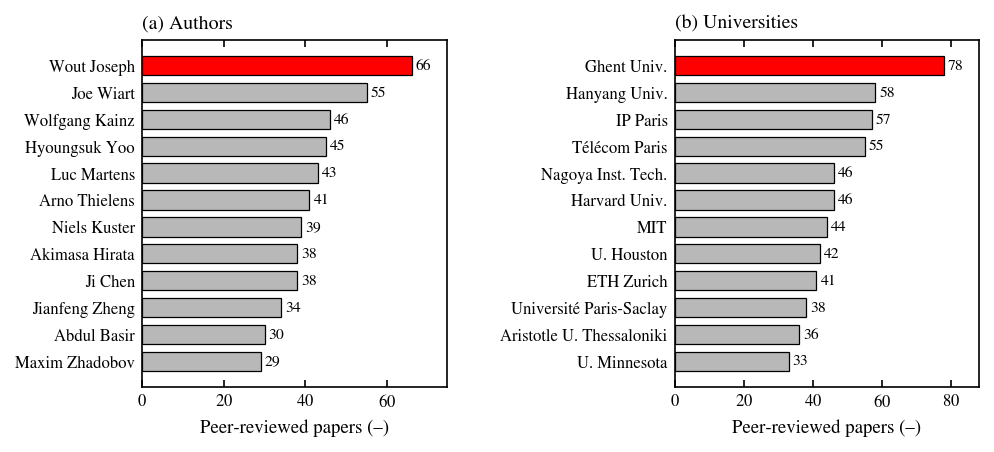

In [3]:
lb.fig_leaders();

**Figure 1.** Wout Joseph has the most RF-EMF dosimetric papers of all authors (a), and Ghent University the most of all universities (b), 2016–2025.
A paper counts once for each author and each institution.
Télécom Paris is part of IP Paris, so its papers appear in both bars.
When research agencies count too, CNRS (France) is first with 116 papers and Ghent University second.

## Other metrics

Paper counts are one way to rank people, and there are others.
The table repeats each result with three more metrics, and again with all OpenAlex articles in place of journal papers only.
A lead paper has the person as first or last author.
"First in" counts how many of the 8 variants put Wout Joseph, Ghent University or WAVES on top.
Universities have no lead-paper metric, so they get 6 variants.
Figure 2 shows the rank in each variant.

In [4]:
c = lb.claims()
c[["Papers", "Runner-up", "First in"]]

,Papers,Runner-up,First in
Claim,,,
"Most RF-EMF dosimetric studies, 2016–2025",66,"Joe Wiart, 55",2/8
"Most EMF dosimetric studies, all frequencies, 2016–2025",73,"Akimasa Hirata, 72",1/8
"Most RF-EMF dosimetric studies, all time",141,"Joe Wiart, 125",1/8
"Most RF-EMF field-measurement studies, 2016–2025",43,"Luc Martens, 28",8/8
"Most base-station exposure studies, 2016–2025",37,"Joe Wiart, 31",8/8
"Most 5G/6G exposure studies, 2016–2025",34,"Maxim Zhadobov, 20",6/8
"Ghent University: most RF-EMF dosimetric studies of any university, 2016–2025",78,"Hanyang University, 58",2/6
"WAVES alone: more RF-EMF dosimetric studies than any other university, 2016–2025",73,"Hanyang University, 58",2/6
"Keyword search, no AI labels: most papers with RF-EMF exposure terms, 2016–2025",59,"Martin Röösli, 53",4/8


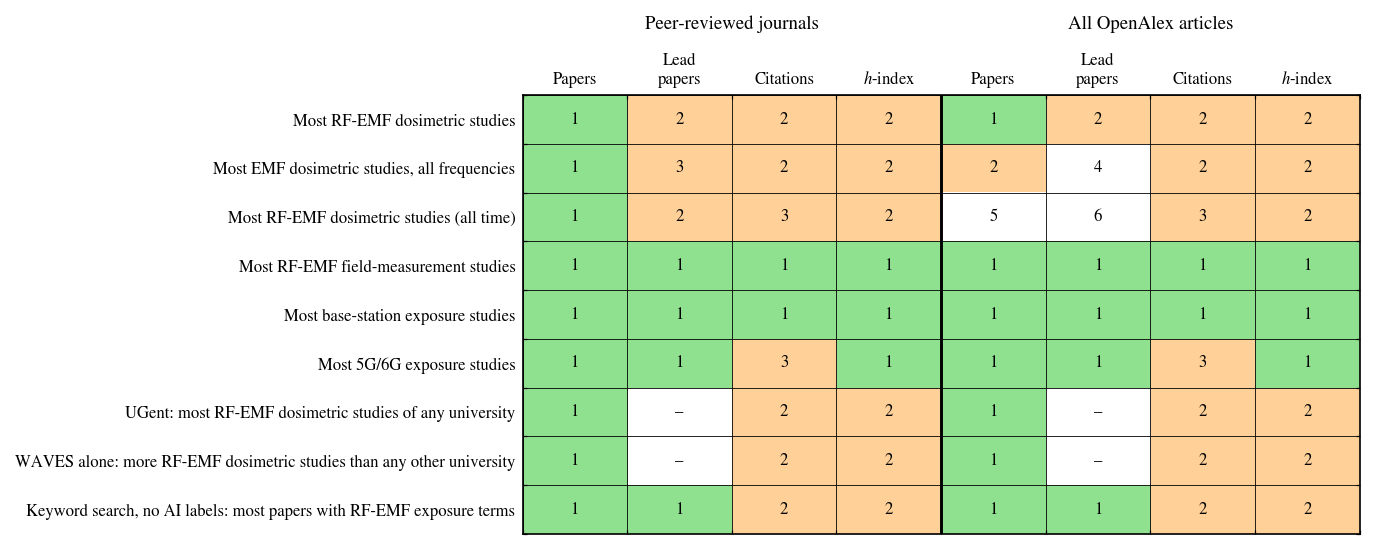

In [5]:
lb.fig_robustness(c);

**Figure 2.** Rank under each metric. Green is first, orange is second or third.
Wout Joseph has the most papers in each row.
For field measurements and base stations, he is first in all 8 variants.
For citations and *h*-index, Hyoungsuk Yoo (Hanyang University) is first in most rows.

## Rankings over time

A ranking for one decade can hide a lot of movement.
Figure 3 follows Wout Joseph and four other leading authors over sliding 5-year windows.

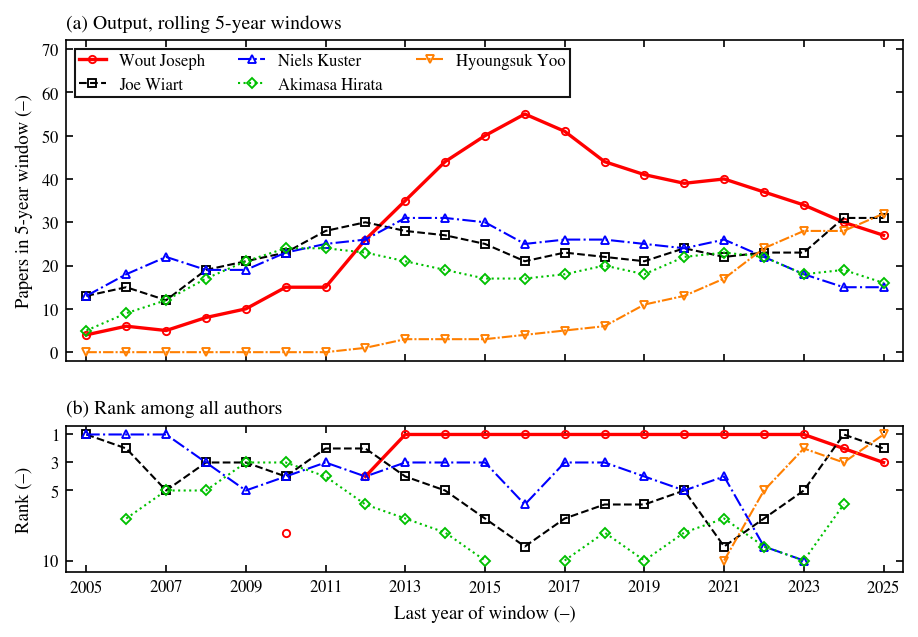

In [6]:
lb.fig_rolling();

**Figure 3.** Wout Joseph had the most RF-EMF dosimetric papers in each 5-year window from 2009–2013 to 2019–2023.
(a) Peer-reviewed papers in the 5 years up to the year on the axis. (b) Rank among all authors.
His output peaked in 2012–2016. In 2021–2025, Hyoungsuk Yoo and Joe Wiart have more papers.

## Rankings by sub-field

No author leads in every sub-field.
Figure 4 gives the rank of Wout Joseph in each sub-field of RF-EMF dosimetry (peer-reviewed, 2016–2025).

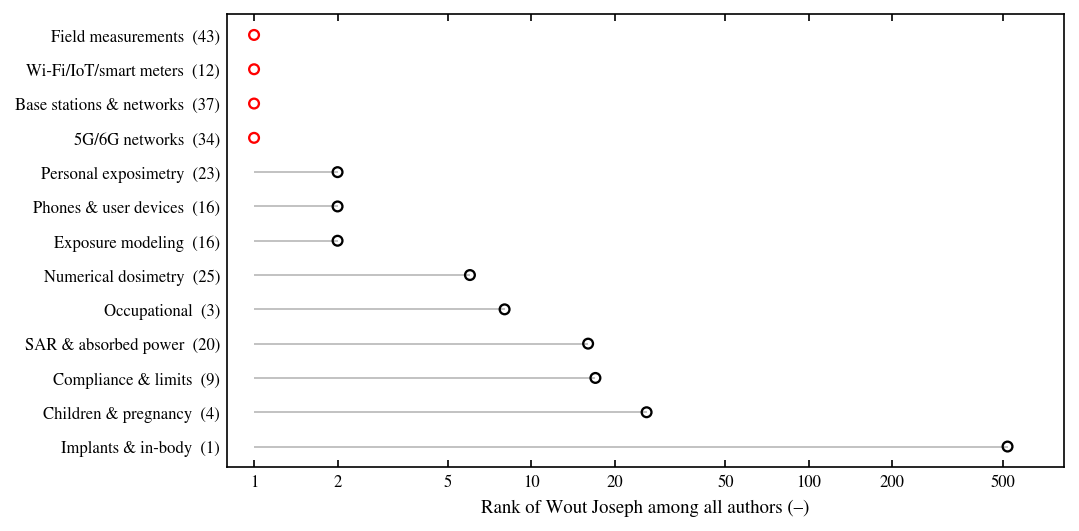

In [7]:
t = lb.topic_ranks()
lb.fig_topics(t);

In [8]:
t

,Rank,Papers,Studies,Leader,Runner-up
Sub-field,,,,,
Field measurements,1,43,624,–,Luc Martens
Wi-Fi/IoT/smart meters,1,12,445,–,Emma Chiaramello
Base stations & networks,1,37,477,–,Joe Wiart
5G/6G networks,1,34,494,–,Luc Martens
Personal exposimetry,2,23,115,Martin Röösli,–
Phones & user devices,2,16,830,Joe Wiart,–
Exposure modeling,2,16,291,Joe Wiart,–
Numerical dosimetry,6,25,1804,Wolfgang Kainz,–
Occupational,8,3,98,Jolanta Karpowicz,–


**Figure 4.** Wout Joseph is first in 4 of 13 sub-fields. His paper count is in brackets.
He is first in the measurement and network sub-fields. Other groups lead SAR, compliance and implants.

## Make your own ranking

Curious about another period, frequency band or sub-field?
Pick the options in the form next to the cell and run it.

In [9]:
entity = "author"  # @param ["author", "university", "institution"]
years = "2016-2025"  # @param ["2016-2025", "2021-2025", "2006-2025", "1980-2026"]
band = "RF"  # @param ["RF", "mmWave", "ELF/IF", "All"]
kind = "Technical/dosimetric"  # @param ["Technical/dosimetric", "Experimental", "Epidemiological", "Any"]
topic = "Any"  # @param ["Any", "Field measurements", "Personal exposimetry", "Numerical dosimetry", "SAR & absorbed power", "5G/6G networks", "Base stations & networks", "Phones & user devices", "Wi-Fi/IoT/smart meters", "Exposure modeling", "Children & pregnancy", "Implants & in-body", "Compliance & limits", "Occupational", "Wireless power transfer"]
metric = "papers"  # @param ["papers", "lead_papers", "citations", "h_index"]
lb.board(entity, metric, n=15, years=tuple(map(int, years.split("-"))), band=band, kind=kind, topic=topic)

,Name,Papers
Rank,,
1,Wout Joseph,66
2,Joe Wiart,55
3,Wolfgang Kainz,46
4,Hyoungsuk Yoo,45
5,Luc Martens,43
6,Arno Thielens,41
7,Niels Kuster,39
8,Akimasa Hirata,38
8,Ji Chen,38


## Comparison with OpenAlex keyword searches

The rankings above rely on the AI labels.
This cell leaves them out: it sends four plain keyword searches to the OpenAlex API (articles and reviews, 2016–2025) and counts papers per author.
The searches also skip the author merges of this repository, so the counts differ from the tables above.
OpenAlex gives each network a small free daily budget. If it runs out, get a free key at [openalex.org](https://openalex.org) and set it with `os.environ["OPENALEX_API_KEY"] = "..."`.

In [10]:
lb.live_check()

,Papers found,#1,#2,#3
Search,,,,
"RF-EMF exposure, broad terms",1024,Martin Röösli (48),Wout Joseph (43),Joe Wiart (34)
RF-EMF measurements,176,Wout Joseph (21),Martin Röösli (19),Raquel Ramírez-Vázquez (17)
Base-station exposure,577,Wout Joseph (24),Joe Wiart (21),Martin Röösli (16)
5G exposure,403,Wout Joseph (23),Davide Colombi (15),Bo Xu (14)


Martin Röösli (Swiss TPH) comes first in the broad search, which also picks up epidemiological studies.
In the searches on measurements, base stations and 5G, Wout Joseph comes first.

## Coverage and label quality

Wout Joseph's full OpenAlex record has 440 articles and reviews over 6 author IDs, and Sonnet labels 188 of them as relevant.
The next cell counts how many of those 188 papers are in the corpus.

In [11]:
found, total = lb.recall()
print(f"{found} of {total} papers ({found / total:.0%})")

165 of 188 papers (88%)


Claude Haiku also labeled 2,000 random papers from the corpus.
The table compares its labels with those of Sonnet on the same papers.

In [12]:
lb.sonnet_vs_haiku()

Papers labeled by both     2000
Same relevance label      90.5%
Same study type           92.8%
dtype: object

Here are eight random papers from the main ranking, with their labels.
Judge for yourself, and run the cell again for a fresh sample.

In [13]:
lb.sample(8)

,Title,Journal,Type
Year,,,
2019,Characterisation of personal exposure to envir...,Environmental Research,Technical
2020,Introduction of the snake antenna array: Geome...,Magnetic Resonance in Medicine,Technical
2021,Performance analysis of integrated RF microstr...,NMR in Biomedicine,Technical
2021,A technique for the reduction of RF‐induced he...,Magnetic Resonance in Medicine,Technical
2021,A Nested Eight-Channel Transmit Array With Ope...,Frontiers in Physics,Technical
2023,A theoretical and experimental investigation o...,Magnetic Resonance Materials in Physics Biolog...,Technical
2025,The effect of wireless and wired headphones on...,PRZEGLĄD ELEKTROTECHNICZNY,Technical
2025,A Flexible Energy Harvesting Metasurface-Based...,IEEE Transactions on Antennas and Propagation,Technical


## Independent reproduction

[`audit_prompt.md`](https://github.com/rwydaegh/rf-emf-leaderboard/blob/main/audit_prompt.md) is a prompt for an impartial audit of this repository.
Paste it into any AI assistant that can run code, such as ChatGPT or Gemini in Colab.

On 14 November 2026, ChatGPT (GPT-6.1 Sol, Work mode, memory off) ran this prompt on commit `5656e2c`, tagged `audited`.
It reproduced every ranking and passed 7 of 8 claims.
For the eighth, it read 30 random papers by Wout Joseph and agreed with the labels of 28.
It would leave out a comment on another study and a short 5G overview.
Without those two papers, Wout Joseph has 64 papers and is still first.
Every other rank holds too, apart from a tie with Joe Wiart on base-station lead papers.
Its verdict is PARTIALLY VERIFIED. The open point is coverage: the audit cannot compare how completely each author's papers were found.

Full report: [chatgpt.com/share/6af8ab58-7980-83ed-aca6-cc6e3aca135f](https://chatgpt.com/share/6af8ab58-7980-83ed-aca6-cc6e3aca135f).
The code and data here are the same as in the audited commit. Check with `git diff audited main -- lb.py src data`.

## Method

1. Download all OpenAlex papers in the topic *Electromagnetic Fields and Biological Effects*, plus the results of 21 keyword searches.
2. Remove duplicates. Merge author records that share an ORCID, a full name and institution, or co-authors.
3. Give the title and abstract of each paper to Claude Sonnet. It labels relevance, study type, frequency band and sub-fields.
4. Count papers, lead papers, citations and *h*-index per author, institution and country, for each combination of period, band, study type and sub-field.

The full pipeline is in [`src/`](https://github.com/rwydaegh/rf-emf-leaderboard/tree/main/src) and runs with `./run.sh`.
Code: MIT license. Data: OpenAlex (CC0).